# QBO temperature and thermal-wind coupling

## Purpose

Evaluate the QBO temperature signal and its thermal-wind consistency with the wind shear.

## Inputs

Model: the 2012-2013 AMIP hindcasts under `INPUT_DATA_ROOT/<case>/post/atm/180x360_aave` (experiments and initial states in `configs/hind_experiment_config.py`). Monthly CMIP-named `ta` (`cmip_ts/monthly`, 19 pressure levels). References: ERA5 and ERA-Interim monthly pressure-level `ta` (E3SM Diags time series under `OBSERVATION_ROOT`, read lazily and subset to the model levels and 5S-5N). The thermal-wind figures also use the `ua` sections of notebook 01.

## Method

5S-5N cos-lat weighted zonal mean on the model levels (hPa). Amplitudes (half peak-to-peak, RMS, detrended RMS) after removing the month-of-year climatology; the saved section stays raw. Thermal-wind balance gives a strong negative correlation between T′ and ∂U/∂ln p.

## Outputs

`data/hind_atm_eval/qbo/qbo_<SOURCE>_ta_<period>.nc`; figures in `figure/hind_atm_eval/qbo/`:

1. Temperature anomaly sections (`FIELD`/`ANOM_MODE`; default: anomalies from the reference monthly climatology, comparable across sources) and their differences from the reference.
2. Temperature amplitude profiles (seasonal cycle removed) and vertical coherence with `COHERENCE_LEVEL`.
3. corr_t[T′, ∂U/∂ln p] by level, mean over `SHEAR_BAND`.
4. T′ vs ∂U/∂ln p in `SCATTER_LAYER`: (month, level) cloud and layer-mean points with their correlation and slope.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options. Edit this cell for normal changes; it holds plain values only, so `papermill -p` overrides work.

In [ ]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
WORKFLOW_NAME = "hind_atm_eval"

#EXPERIMENTS = ("CTRL", "DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE")
EXPERIMENTS = ("CTRL", "DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE")
REFERENCES = ("ERAI", "ERA5")  # sections for both
REFERENCE = "ERAI"
OTHER_REANALYSIS = "ERA5"
LAT_BAND = (-5.0, 5.0)
FIELD = "qbo_anom"          # "qbo" (raw) | "qbo_anom"
ANOM_MODE = "ref_clim"      # "own_clim" | "ref_clim" | "first_month"
COHERENCE_LEVEL = 30.0      # hPa
SHEAR_BAND = (10.0, 70.0)   # hPa
SCATTER_LAYER = (20.0, 50.0)
SCATTER_SOURCES = ("ERA5", "DARTOP", "ERA5OP", "CTRL", "DARTBA")
FORCE_COMPUTE = False
FONT_SCALE = 14
SHOW = True
FIGURE_DPI = 300
USE_DISTRIBUTED = False  # True: local dask.distributed cluster; worker processes read files in parallel
DASK_WORKERS = 8         # threads (threaded scheduler) or worker processes (distributed); bounds memory

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.dask_helpers import compute_all, configure_dask

client = configure_dask(use_distributed=USE_DISTRIBUTED, n_workers=DASK_WORKERS, n_threads=DASK_WORKERS)
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, 'qbo', output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(observation_root=OBSERVATION_ROOT)
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")

def save(fig, name):
    path = figure_dir / name
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo


## 4. Read input

Saved diagnostics are reused: fields are opened lazily only for the sources whose output file is missing (all of them with `FORCE_COMPUTE`), and loaded in the Derive step. The `ua` sections of notebook 01 must exist.

In [4]:
from configs.hind_experiment_config import PERIOD
from util.qbo_diagnostics import open_qbo_input, qbo_section_path

VARIABLE = "ta"
SOURCES = (*REFERENCES, *EXPERIMENTS)
missing = [s for s in dict.fromkeys((*SOURCES, *SCATTER_SOURCES)) if not qbo_section_path(data_dir, s, "ua").exists()]
if missing:
    raise FileNotFoundError(f"ua sections of {missing} not found: run 01_compute_and_plot_qbo_wind.ipynb first")
paths = {s: qbo_section_path(data_dir, s, VARIABLE) for s in SOURCES}
inputs = {s: open_qbo_input(s, VARIABLE, data_root=INPUT_DATA_ROOT, **ROOTS)
          for s in SOURCES if FORCE_COMPUTE or not paths[s].exists()}
print(f"[READ] {', '.join(inputs) or 'nothing: every section is saved'}")

[READ] nothing: every section is saved


## 5. Derive

Equatorial time-height section and amplitude profiles (seasonal cycle removed) per source. The expensive reductions of every source are computed together in one Dask graph (`compute_all`), so reads and reductions run in parallel; the rest works on the loaded results.

In [5]:
from util.qbo_diagnostics import QboAnalyzer, QboConfig

analyzer = QboAnalyzer(QboConfig.for_variable(VARIABLE, lat_band=LAT_BAND))
reduced = compute_all({s: analyzer.reduce(da) for s, da in inputs.items()})
derived = {s: analyzer.compute_metrics(f"{s}_{VARIABLE}_{PERIOD}", da).assign_attrs(source=s)
           for s, da in reduced.items()}

## 6. Save

Write the newly derived files, then reload every source from disk so the steps below use the same data as a rerun that reuses the files. Check: RMS amplitude at 30 hPa per source.

In [6]:
for s, ds in derived.items():
    ds.to_netcdf(paths[s])
    print(f"[WRITE] {paths[s]}")
sections = {s: xr.load_dataset(p) for s, p in paths.items()}
display(pd.Series({s: float(ds.amp_rms.sel(plev=30)) for s, ds in sections.items()},
                  name="amp_rms_30hPa").round(2))

ERAI      1.96
ERA5      1.99
CTRL      1.73
DARTOP    1.63
ERA5OP    2.40
ERA5DL    2.18
ERA5BL    2.53
DARTBL    1.62
DARTBA    1.80
DARTAE    1.74
Name: amp_rms_30hPa, dtype: float64

## 7. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ta_ref_clim_sections_vs_ERAI.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ta_ref_clim_diffs_vs_ERAI.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ta_amplitude_rms.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ta_ref_clim_coherence_30hPa.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_t_shear_corr_profiles.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_t_shear_scatter_20-50hPa.png


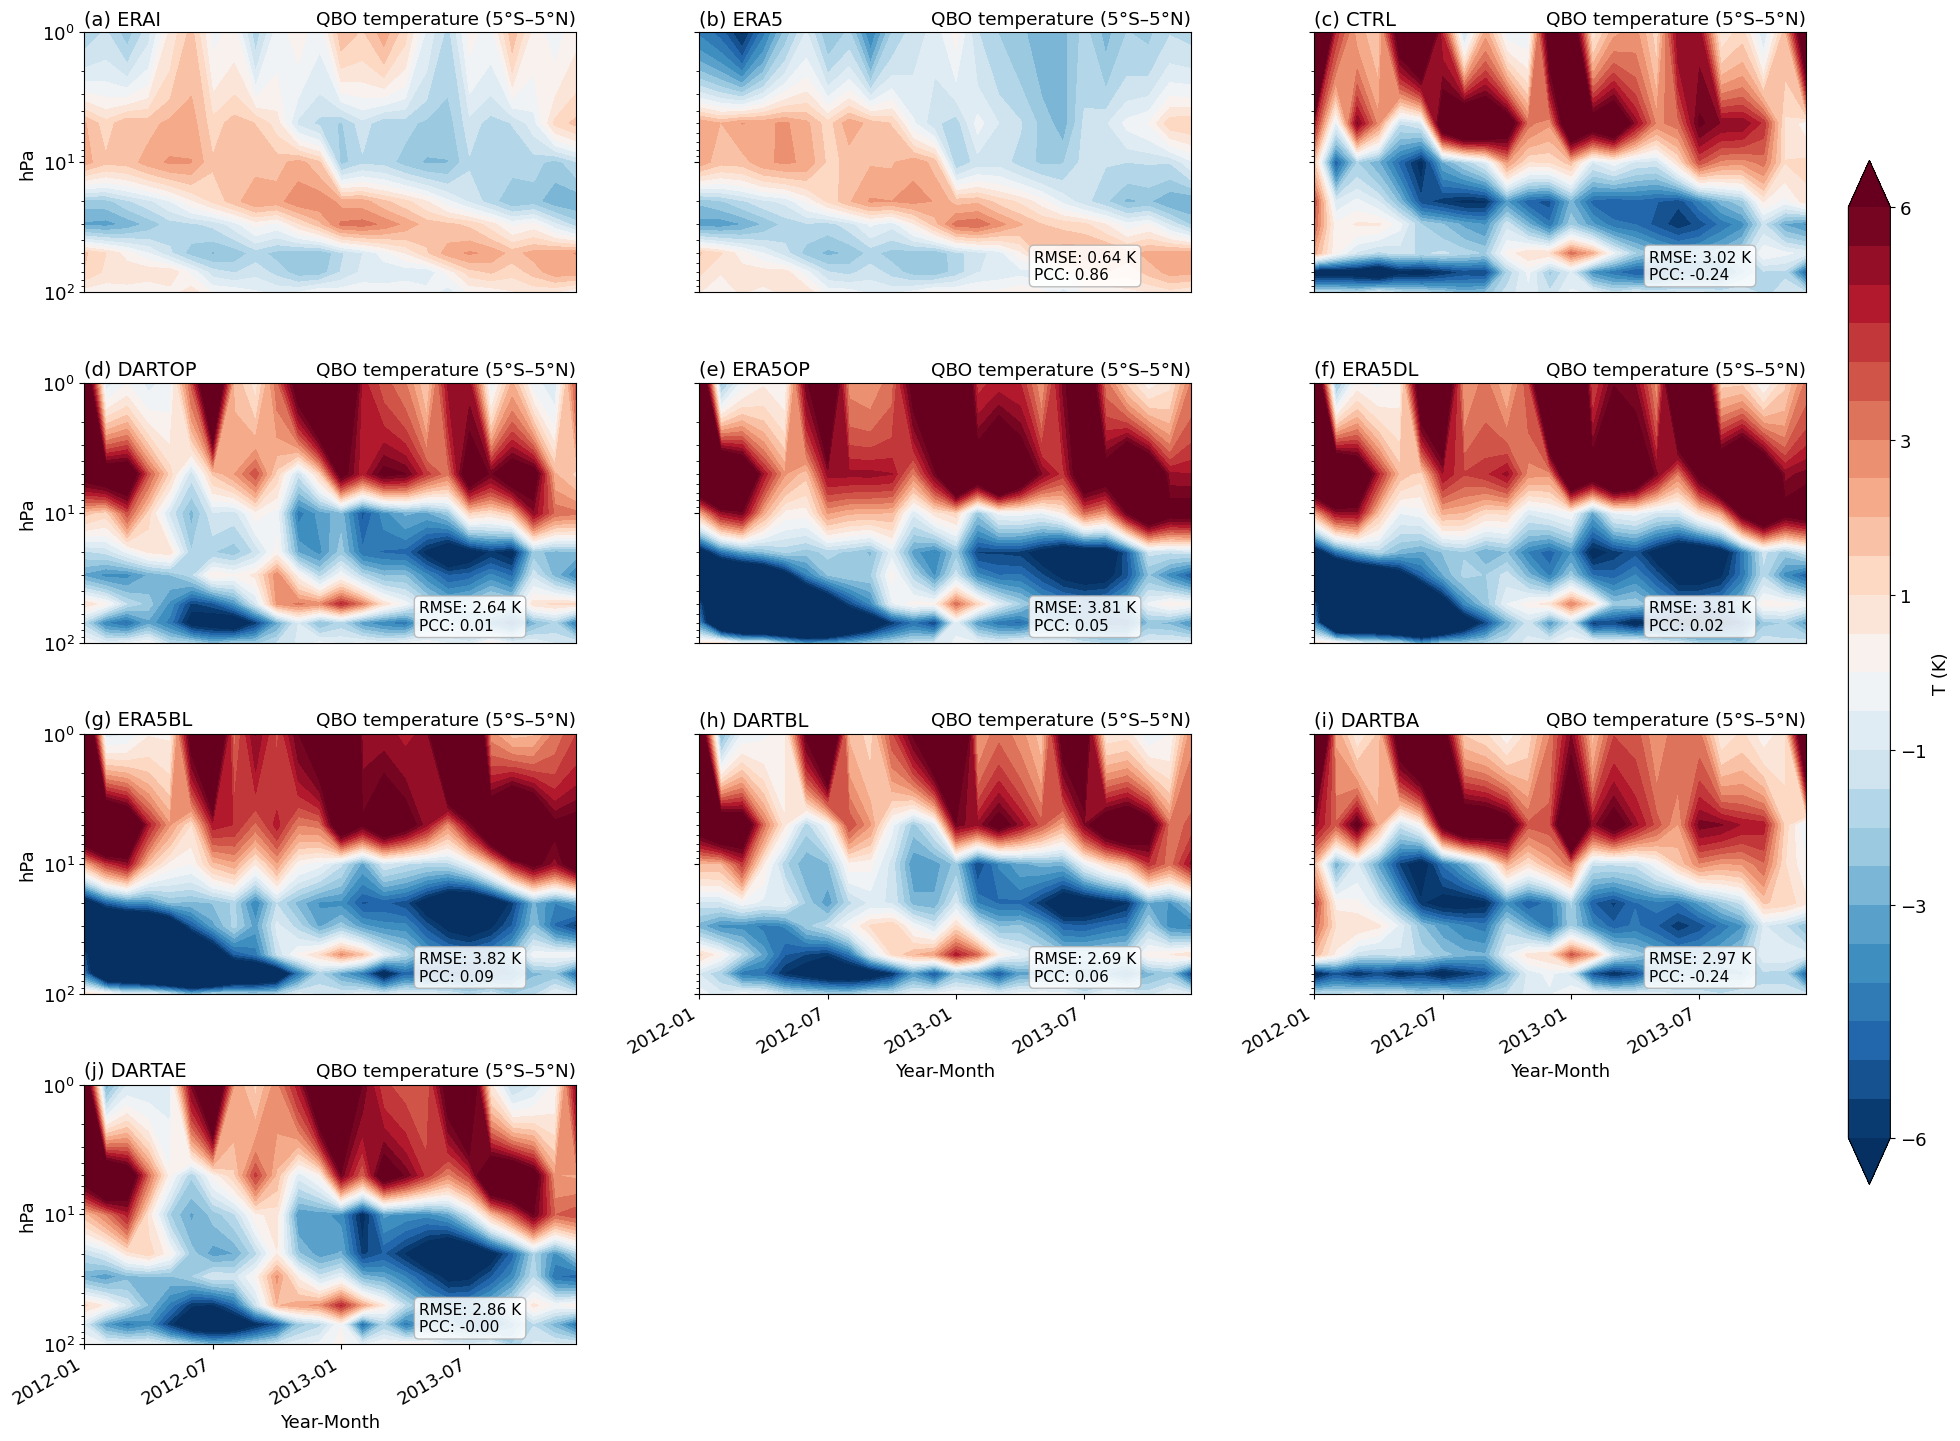

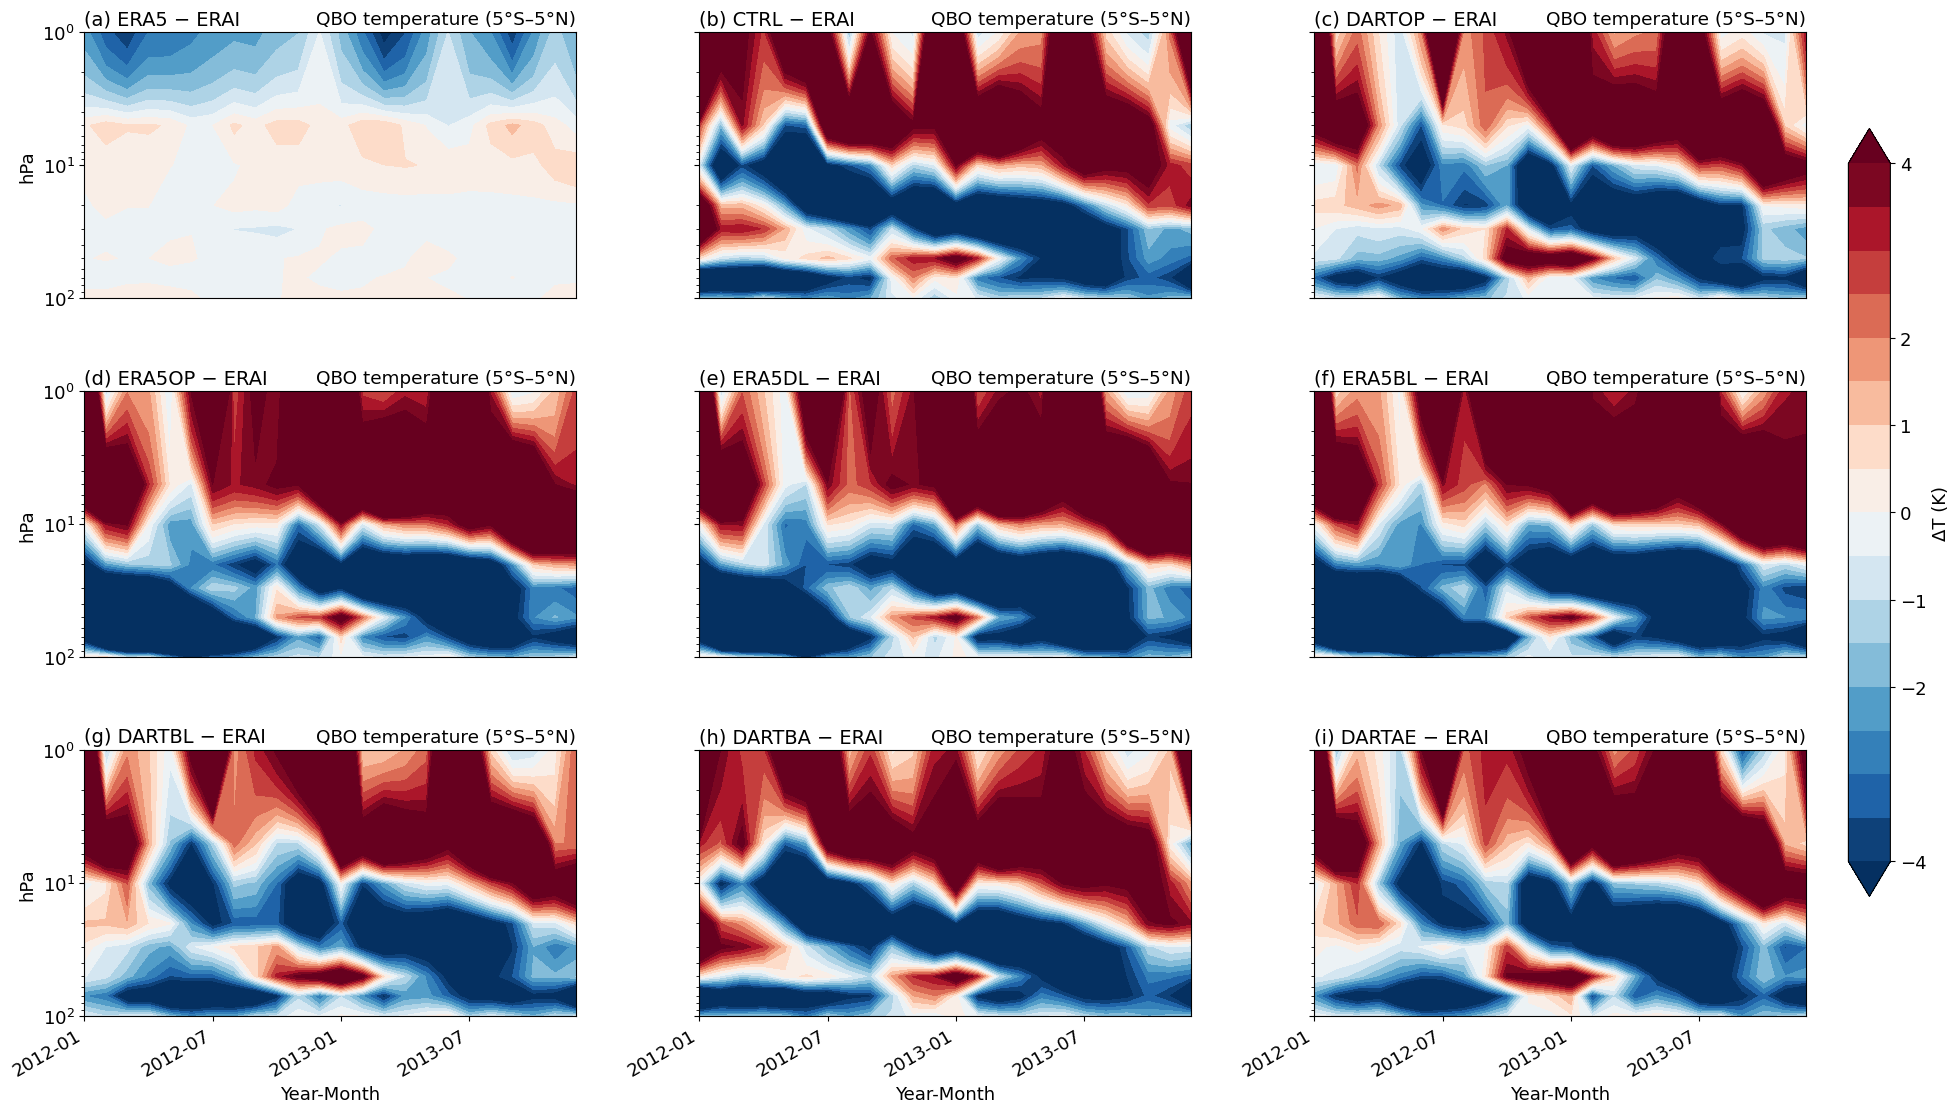

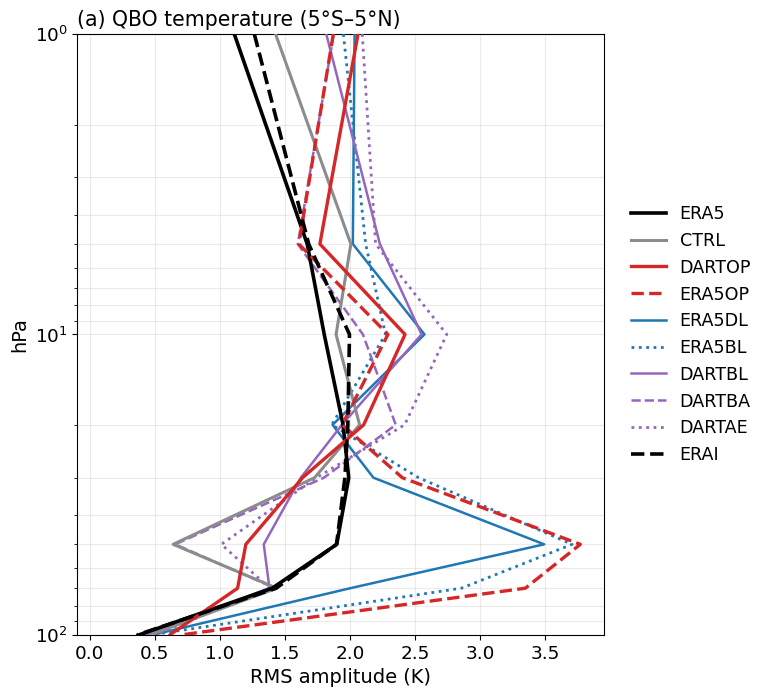

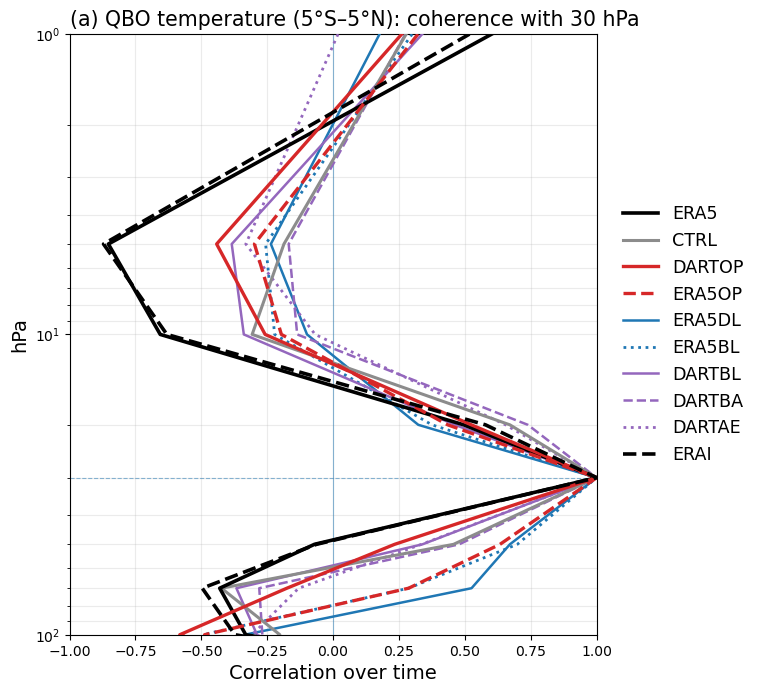

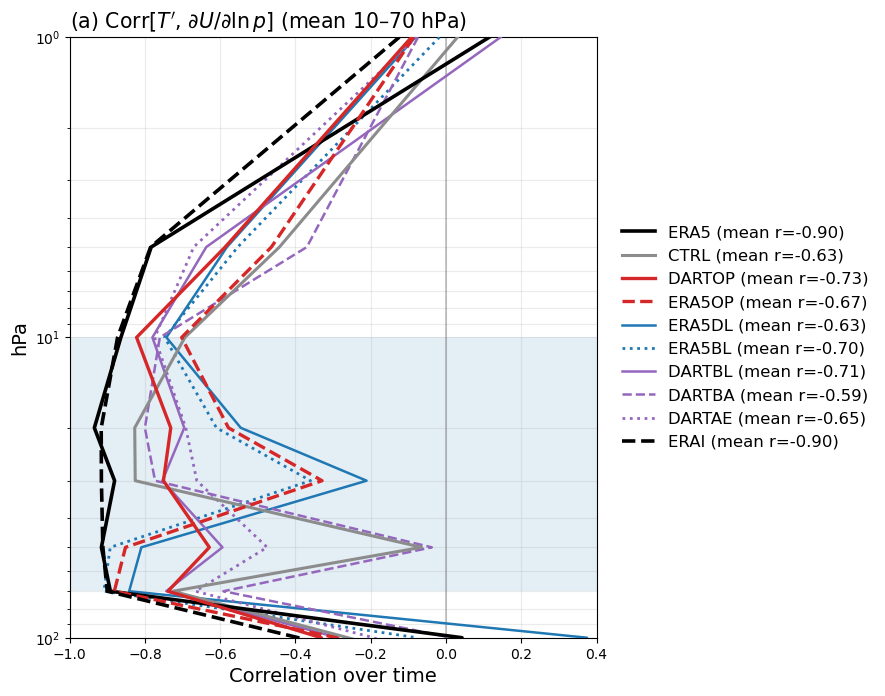

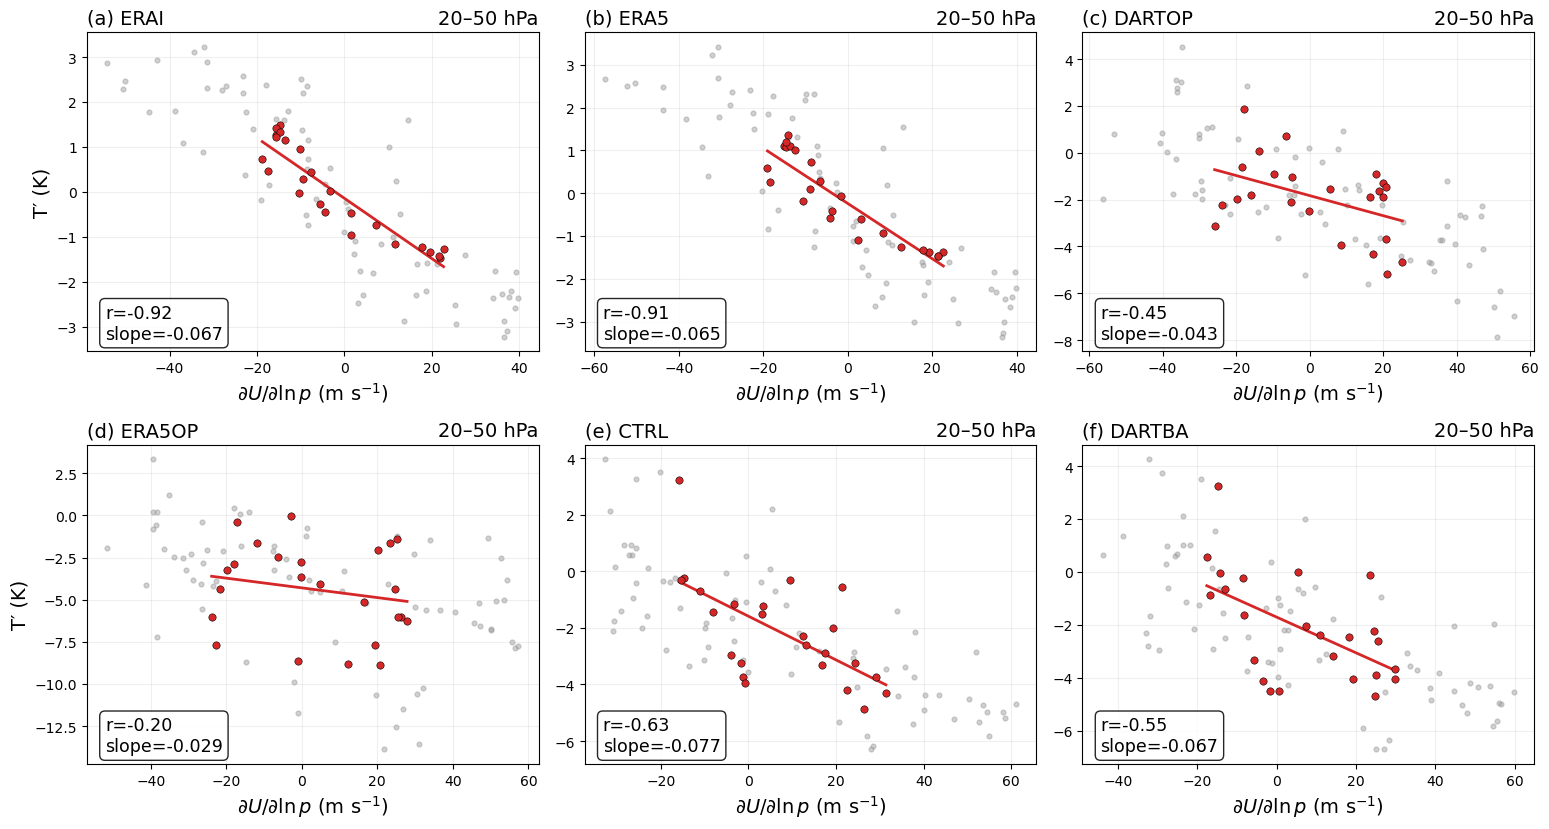

In [7]:
from util.qbo_plotting import (QboPlotParameter, QboPlotter, plot_t_shear_corr_profiles,
                               plot_t_shear_scatter)

plotter = QboPlotter(QboPlotParameter.for_variable(VARIABLE, default_field=FIELD, default_anom_mode=ANOM_MODE),
                     data_dir)
sources = [OTHER_REANALYSIS, *EXPERIMENTS]
tag = "raw" if FIELD == "qbo" else ANOM_MODE
save(plotter.plot_timepressure(REFERENCE, sources, font_scale=FONT_SCALE, w_per_col=7, h_per_row=4),
     f"qbo_ta_{tag}_sections_vs_{REFERENCE}.png")
save(plotter.plot_timepressure_diffs(REFERENCE, sources, font_scale=FONT_SCALE, w_per_col=7, h_per_row=4),
     f"qbo_ta_{tag}_diffs_vs_{REFERENCE}.png")
save(plotter.plot_amplitude(REFERENCE, sources, font_scale=FONT_SCALE), "qbo_ta_amplitude_rms.png")
save(plotter.plot_vertical_coherence(REFERENCE, sources, ref_level_hpa=COHERENCE_LEVEL, font_scale=FONT_SCALE),
     f"qbo_ta_{tag}_coherence_{COHERENCE_LEVEL:g}hPa.png")
save(plot_t_shear_corr_profiles(data_dir, REFERENCE, sources, band_hpa=SHEAR_BAND, xlim=(-1.0, 0.4),
                                font_scale=FONT_SCALE), "qbo_t_shear_corr_profiles.png")
save(plot_t_shear_scatter(data_dir, REFERENCE, SCATTER_SOURCES, layer_hpa=SCATTER_LAYER, font_scale=FONT_SCALE),
     f"qbo_t_shear_scatter_{SCATTER_LAYER[0]:g}-{SCATTER_LAYER[1]:g}hPa.png")